some trained models:

1. model_1: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=10, BATCH_SIZE=4, train.nlayer=4

1. model_1_GMM: GMM of Helen, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=10, BATCH_SIZE=4, train.nlayer=4

1. model_1_default: DefaultGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=10, BATCH_SIZE=4, train.nlayer=4

2. model_2: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=20, BATCH_SIZE=4, train.nlayer=4

2. model_2_GMM: GMM of Helen, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=20, BATCH_SIZE=4, train.nlayer=4

2. model_2_default: DefaultGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=20, BATCH_SIZE=4, train.nlayer=4

3. model_3: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=30, BATCH_SIZE=4, train.nlayer=4

3. model_3_GMM: GMM of Helen, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=30, BATCH_SIZE=4, train.nlayer=4

3. model_3_default: DefaultGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=30, BATCH_SIZE=4, train.nlayer=4



https://neptune.ai/blog/f1-score-accuracy-roc-auc-pr-auc

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

In [2]:
# path of models to extract training time
model_1_train_val_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E10.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_1_GMM_train_val_loss = "../ckpt/dataGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E10.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_1_default_train_val_loss = "../ckpt/context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E10.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/seed0/train_val_loss.pickle"

model_2_train_val_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E20.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_2_GMM_train_val_loss = "../ckpt/dataGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E20.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_2_default_train_val_loss = "../ckpt/context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E20.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/seed0/train_val_loss.pickle"

model_3_train_val_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E30.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_3_GMM_train_val_loss = "../ckpt/dataGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E30.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_3_default_train_val_loss = "../ckpt/context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E30.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/seed0/train_val_loss.pickle"

# paths of models
model_1_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E10.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_1_GMM_dir = "../results/adbench/dataGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E10.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_1_default_dir = "../results/adbench/context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E10.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"

model_2_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E20.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_2_GMM_dir = "../results/adbench/dataGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E20.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_2_default_dir = "../results/adbench/context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E20.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"

model_3_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E30.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_3_GMM_dir = "../results/adbench/dataGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E30.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_3_default_dir = "../results/adbench/context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E30.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"




### 1. Model_1_SGMM

In [3]:
with open(model_1_train_val_loss, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
model_1_train_time = data['train_time']

print("Train time in second", model_1_train_time)
model_1_aucroc_scores = []
model_1_aucpr_scores = []
model_1_f1_scores = []
model_1_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_1_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_1_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_1_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_1_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_1_time_per_instance.append(time_instance)


# compute average scores of all datasets
model_1_avg_aucroc = sum(model_1_aucroc_scores) / len(model_1_aucroc_scores)
model_1_avg_aucpr = sum(model_1_aucpr_scores) / len(model_1_aucpr_scores)
model_1_avg_f1 = sum(model_1_f1_scores) / len(model_1_f1_scores)
model_1_time_per_instance_avg = sum(model_1_time_per_instance) / len(model_1_time_per_instance)

print(f"number of datasets: {len(model_1_aucroc_scores)}")
print(f"Average aucroc: {model_1_avg_aucroc}")
print(f"Average aucpr: {model_1_avg_aucpr}")
print(f"Average f1: {model_1_avg_f1}")
print(f"Inference time per instance: {model_1_time_per_instance_avg}")

Train time in second 2470.707485437393
number of datasets: 121
Average aucroc: 0.7333058889362173
Average aucpr: 0.4213088402128753
Average f1: 0.41829633910560815
Inference time per instance: 4.979171702239355e-06


### 1. model_1_GMM

In [4]:
with open(model_1_GMM_train_val_loss, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
model_1_GMM_train_time = data['train_time']
print("Train time", model_1_GMM_train_time)

model_1_GMM_aucroc_scores = []
model_1_GMM_aucpr_scores = []
model_1_GMM_f1_scores = []
model_1_GMM_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_1_GMM_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_1_GMM_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_1_GMM_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_1_GMM_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_1_GMM_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_1_GMM_avg_aucroc = sum(model_1_GMM_aucroc_scores) / len(model_1_GMM_aucroc_scores)
model_1_GMM_avg_aucpr = sum(model_1_GMM_aucpr_scores) / len(model_1_GMM_aucpr_scores)
model_1_GMM_avg_f1 = sum(model_1_GMM_f1_scores) / len(model_1_GMM_f1_scores)
model_1_GMM_time_per_instance_avg = sum(model_1_GMM_time_per_instance) / len(model_1_GMM_time_per_instance)

print(f"number of datasets: {len(model_1_GMM_aucroc_scores)}")
print(f"Average aucroc: {model_1_GMM_avg_aucroc}")
print(f"Average aucpr: {model_1_GMM_avg_aucpr}")
print(f"Average f1: {model_1_GMM_avg_f1}")
print(f"Inference time per instance: {model_1_GMM_time_per_instance_avg}")

Train time 25693.671844005585
number of datasets: 121
Average aucroc: 0.7246604094223407
Average aucpr: 0.44037903363482195
Average f1: 0.423861753110368
Inference time per instance: 4.928848867185269e-06


### 1. model_1_default

In [5]:
with open(model_1_default_train_val_loss, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
model_1_default_train_time = data['train_time']
print("Train time", model_1_default_train_time)

model_1_default_aucroc_scores = []
model_1_default_aucpr_scores = []
model_1_default_f1_scores = []
model_1_default_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_1_default_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_1_default_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_1_default_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_1_default_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_1_default_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_1_default_avg_aucroc = sum(model_1_default_aucroc_scores) / len(model_1_default_aucroc_scores)
model_1_default_avg_aucpr = sum(model_1_default_aucpr_scores) / len(model_1_default_aucpr_scores)
model_1_default_avg_f1 = sum(model_1_default_f1_scores) / len(model_1_default_f1_scores)
model_1_default_time_per_instance_avg = sum(model_1_default_time_per_instance) / len(model_1_default_time_per_instance)

print(f"number of datasets: {len(model_1_default_aucroc_scores)}")
print(f"Average aucroc: {model_1_default_avg_aucroc}")
print(f"Average aucpr: {model_1_default_avg_aucpr}")
print(f"Average f1: {model_1_default_avg_f1}")
print(f"Inference time per instance: {model_1_default_time_per_instance_avg}") 

Train time 26246.57777786255
number of datasets: 121
Average aucroc: 0.7208075033835809
Average aucpr: 0.43407800055837914
Average f1: 0.41441545764379917
Inference time per instance: 4.794142338001615e-06


### 2. Model_2

In [6]:
with open(model_2_train_val_loss, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
model_2_train_time = data['train_time']

print("Train time", model_2_train_time)

model_2_aucroc_scores = []
model_2_aucpr_scores = []
model_2_f1_scores = []
model_2_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_2_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_2_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_2_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_2_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_2_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_2_avg_aucroc = sum(model_2_aucroc_scores) / len(model_2_aucroc_scores)
model_2_avg_aucpr = sum(model_2_aucpr_scores) / len(model_2_aucpr_scores)
model_2_avg_f1 = sum(model_2_f1_scores) / len(model_2_f1_scores)
model_2_time_per_instance_avg = sum(model_2_time_per_instance) / len(model_2_time_per_instance)

print(f"number of datasets: {len(model_2_aucroc_scores)}")
print(f"Average aucroc: {model_2_avg_aucroc}")
print(f"Average aucpr: {model_2_avg_aucpr}")
print(f"Average f1: {model_2_avg_f1}")
print(f"Inference time per instance: {model_2_time_per_instance_avg}") 

Train time 4964.264281272888
number of datasets: 121
Average aucroc: 0.7390339279358105
Average aucpr: 0.4290496053067343
Average f1: 0.4236439439623536
Inference time per instance: 5.0105296823407135e-06


### 2. model_2_GMM

In [7]:
with open(model_2_GMM_train_val_loss, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
model_2_GMM_train_time = data['train_time']

print("Train time", model_2_GMM_train_time)
model_2_GMM_aucroc_scores = []
model_2_GMM_aucpr_scores = []
model_2_GMM_f1_scores = []
model_2_GMM_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_2_GMM_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_2_GMM_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_2_GMM_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_2_GMM_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_2_GMM_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_2_GMM_avg_aucroc = sum(model_2_GMM_aucroc_scores) / len(model_2_GMM_aucroc_scores)
model_2_GMM_avg_aucpr = sum(model_2_GMM_aucpr_scores) / len(model_2_GMM_aucpr_scores)
model_2_GMM_avg_f1 = sum(model_2_GMM_f1_scores) / len(model_2_GMM_f1_scores)
model_2_GMM_time_per_instance_avg = sum(model_2_GMM_time_per_instance) / len(model_2_GMM_time_per_instance)

print(f"number of datasets: {len(model_2_GMM_aucroc_scores)}")
print(f"Average aucroc: {model_2_GMM_avg_aucroc}")
print(f"Average aucpr: {model_2_GMM_avg_aucpr}")
print(f"Average f1: {model_2_GMM_avg_f1}")
print(f"Inference time per instance: {model_2_GMM_time_per_instance_avg}") 

Train time 52209.615515232086
number of datasets: 121
Average aucroc: 0.7264488263694614
Average aucpr: 0.4428387001249094
Average f1: 0.42700672159681446
Inference time per instance: 4.842716862776499e-06


### 2. model_2_default

In [8]:
with open(model_2_default_train_val_loss, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
model_2_default_train_time = data['train_time']

print("Train time", model_2_default_train_time)

model_2_default_aucroc_scores = []
model_2_default_aucpr_scores = []
model_2_default_f1_scores = []
model_2_default_time_per_instance = []

# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_2_default_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_2_default_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_2_default_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_2_default_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_2_default_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_2_default_avg_aucroc = sum(model_2_default_aucroc_scores) / len(model_2_default_aucroc_scores)
model_2_default_avg_aucpr = sum(model_2_default_aucpr_scores) / len(model_2_default_aucpr_scores)
model_2_default_avg_f1 = sum(model_2_default_f1_scores) / len(model_2_default_f1_scores)
model_2_default_time_per_instance_avg = sum(model_2_default_time_per_instance) / len(model_2_default_time_per_instance)

print(f"number of datasets: {len(model_2_default_aucroc_scores)}")
print(f"Average aucroc: {model_2_default_avg_aucroc}")
print(f"Average aucpr: {model_2_default_avg_aucpr}")
print(f"Average f1: {model_2_default_avg_f1}")
print(f"Inference time per instance: {model_2_default_time_per_instance_avg}") 

Train time 52985.72168326378
number of datasets: 121
Average aucroc: 0.7204389699896803
Average aucpr: 0.43818098871437244
Average f1: 0.4254930578936309
Inference time per instance: 4.9483684127379725e-06


### 3. Model_3

In [9]:
with open(model_3_train_val_loss, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
model_3_train_time = data['train_time']

print("Train time", model_3_train_time)
model_3_aucroc_scores = []
model_3_aucpr_scores = []
model_3_f1_scores = []
model_3_time_per_instance = []

# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_3_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_3_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_3_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_3_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_3_time_per_instance.append(time_instance)



# compute average scores of all datasets
model_3_avg_aucroc = sum(model_3_aucroc_scores) / len(model_3_aucroc_scores)
model_3_avg_aucpr = sum(model_3_aucpr_scores) / len(model_3_aucpr_scores)
model_3_avg_f1 = sum(model_3_f1_scores) / len(model_3_f1_scores)
model_3_time_per_instance_avg = sum(model_3_time_per_instance) / len(model_3_time_per_instance)

print(f"number of datasets: {len(model_3_aucroc_scores)}")
print(f"Average aucroc: {model_3_avg_aucroc}")
print(f"Average aucpr: {model_3_avg_aucpr}")
print(f"Average f1: {model_3_avg_f1}")
print(f"Inference time per instance: {model_3_time_per_instance_avg}") 

Train time 9731.507739782333
number of datasets: 121
Average aucroc: 0.7201614607957915
Average aucpr: 0.4090241869719313
Average f1: 0.406593320118213
Inference time per instance: 1.0350580729375283e-05


### 3. model_3_GMM

In [10]:
with open(model_3_GMM_train_val_loss, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
model_3_GMM_train_time = data['train_time']

print("Train time", model_3_GMM_train_time)

model_3_GMM_aucroc_scores = []
model_3_GMM_aucpr_scores = []
model_3_GMM_f1_scores = []
model_3_GMM_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_3_GMM_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_3_GMM_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_3_GMM_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_3_GMM_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_3_GMM_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_3_GMM_avg_aucroc = sum(model_3_GMM_aucroc_scores) / len(model_3_GMM_aucroc_scores)
model_3_GMM_avg_aucpr = sum(model_3_GMM_aucpr_scores) / len(model_3_GMM_aucpr_scores)
model_3_GMM_avg_f1 = sum(model_3_GMM_f1_scores) / len(model_3_GMM_f1_scores)
model_3_GMM_time_per_instance_avg = sum(model_3_GMM_time_per_instance) / len(model_3_GMM_time_per_instance)

print(f"number of datasets: {len(model_3_GMM_aucroc_scores)}")
print(f"Average aucroc: {model_3_GMM_avg_aucroc}")
print(f"Average aucpr: {model_3_GMM_avg_aucpr}")
print(f"Average f1: {model_3_GMM_avg_f1}")
print(f"Inference time per instance: {model_3_GMM_time_per_instance_avg}") 

Train time 78929.41522741318
number of datasets: 121
Average aucroc: 0.7184212572010811
Average aucpr: 0.43676666412481074
Average f1: 0.4193413176325299
Inference time per instance: 4.872612055351394e-06


### 3. model_3_default

In [11]:
with open(model_3_default_train_val_loss, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
model_3_default_train_time = data['train_time']

print("Train time", model_3_default_train_time)

model_3_default_aucroc_scores = []
model_3_default_aucpr_scores = []
model_3_default_f1_scores = []
model_3_default_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_3_default_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_3_default_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_3_default_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_3_default_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_3_default_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_3_default_avg_aucroc = sum(model_3_default_aucroc_scores) / len(model_3_default_aucroc_scores)
model_3_default_avg_aucpr = sum(model_3_default_aucpr_scores) / len(model_3_default_aucpr_scores)
model_3_default_avg_f1 = sum(model_3_default_f1_scores) / len(model_3_default_f1_scores)
model_3_default_time_per_instance_avg = sum(model_3_default_time_per_instance) / len(model_3_default_time_per_instance)

print(f"number of datasets: {len(model_3_default_aucroc_scores)}")
print(f"Average aucroc: {model_3_default_avg_aucroc}")
print(f"Average aucpr: {model_3_default_avg_aucpr}")
print(f"Average f1: {model_3_default_avg_f1}")
print(f"Inference time per instance: {model_3_default_time_per_instance_avg}") 

Train time 78954.45132613182
number of datasets: 121
Average aucroc: 0.7256278517768739
Average aucpr: 0.44394664583280247
Average f1: 0.43170945801358523
Inference time per instance: 4.912014324345205e-06


### Visualization

In [12]:
models = ['model_1_default', 'model_1_MGMM', 'model_1_CMM', 'model_2_default', 'model_2_MGMM', 'model_2_CMM', 'model_3_default', 'model_3_MGMM', 'model_3_CMM']
data_prior_group = ['GMM', 'MGMM', 'CMM', 'GMM', 'MGMM', 'CMM', 'GMM', 'MGMM', 'CMM']
avg_aucroc_scores = [round(model_1_default_avg_aucroc, 4), round(model_1_GMM_avg_aucroc, 4), round(model_1_avg_aucroc, 4), round(model_2_default_avg_aucroc, 4), round(model_2_GMM_avg_aucroc, 4), round(model_2_avg_aucroc, 4), round(model_3_default_avg_aucroc, 4), round(model_3_GMM_avg_aucroc, 4), round(model_3_avg_aucroc, 4)]
avg_aucpr_scores = [round(model_1_default_avg_aucpr, 4), round(model_1_GMM_avg_aucpr, 4), round(model_1_avg_aucpr, 4), round(model_2_default_avg_aucpr, 4), round(model_2_GMM_avg_aucpr, 4), round(model_2_avg_aucpr, 4), round(model_3_default_avg_aucpr, 4), round(model_3_GMM_avg_aucpr, 4), round(model_3_avg_aucpr, 4)]
avg_f1_scores = [round(model_1_default_avg_f1, 4), round(model_1_GMM_avg_f1, 4), round(model_1_avg_f1, 4), round(model_2_default_avg_f1, 4), round(model_2_GMM_avg_f1, 4), round(model_2_avg_f1, 4), round(model_3_default_avg_f1, 4), round(model_3_GMM_avg_f1, 4), round(model_3_avg_f1, 4)]
# training time is in seconds
training_time = [round(model_1_default_train_time, 2), round(model_1_GMM_train_time, 2), round(model_1_train_time, 2), round(model_2_default_train_time, 2), round(model_2_GMM_train_time, 2), round(model_2_train_time, 2), round(model_3_default_train_time, 2), round(model_3_GMM_train_time, 2), round(model_3_train_time, 2)]
# inference time is in microseconds (µs)
inference_time = [model_1_default_time_per_instance_avg * 1e6, model_1_GMM_time_per_instance_avg * 1e6, model_1_time_per_instance_avg * 1e6, model_2_default_time_per_instance_avg * 1e6, model_2_GMM_time_per_instance_avg * 1e6, model_2_time_per_instance_avg * 1e6, model_3_default_time_per_instance_avg * 1e6, model_3_GMM_time_per_instance_avg * 1e6, model_3_time_per_instance_avg * 1e6]

summary_dict = {'models': models, 'data_prior_group': data_prior_group,'average_aucroc': avg_aucroc_scores, 'average_aucpr': avg_aucpr_scores, 'average_f1': avg_f1_scores, 'training_time(s)': training_time, 'inference_time(µs)': inference_time}


In [13]:
summary_results = pd.DataFrame(summary_dict)
summary_results

,models,data_prior_group,average_aucroc,average_aucpr,average_f1,training_time(s),inference_time(µs)
0,model_1_default,GMM,0.7208,0.4341,0.4144,26246.58,4.794142
1,model_1_MGMM,MGMM,0.7247,0.4404,0.4239,25693.67,4.928849
2,model_1_CMM,CMM,0.7333,0.4213,0.4183,2470.71,4.979172
3,model_2_default,GMM,0.7204,0.4382,0.4255,52985.72,4.948368
4,model_2_MGMM,MGMM,0.7264,0.4428,0.4270,52209.62,4.842717
5,model_2_CMM,CMM,0.7390,0.4290,0.4236,4964.26,5.010530
6,model_3_default,GMM,0.7256,0.4439,0.4317,78954.45,4.912014
7,model_3_MGMM,MGMM,0.7184,0.4368,0.4193,78929.42,4.872612
8,model_3_CMM,CMM,0.7202,0.4090,0.4066,9731.51,10.350581


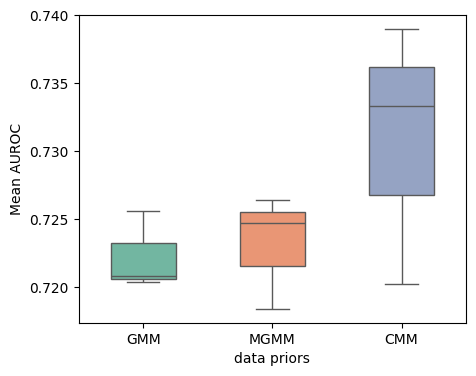

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
#fig, ax = plt.subplots(figsize=(6,5))
#sns.color_palette("pastel")
plt.figure(figsize=(5,4))
sns.boxplot(data=summary_results, x="data_prior_group", y='average_aucroc', hue="data_prior_group", palette="Set2", legend='auto', width=0.5)
plt.xlabel("data priors")
plt.ylabel("Mean AUROC")
#plt.savefig('data_priors_impact.png')
#plt.savefig('data_priors_impact.png', dpi=300, bbox_inches='tight')

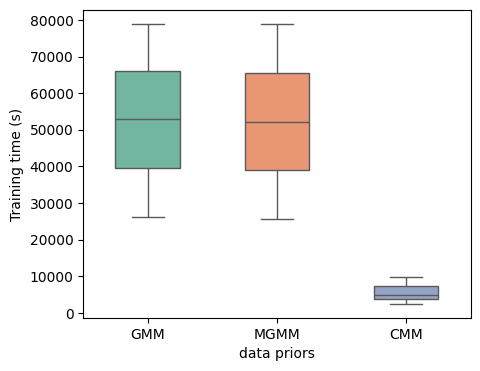

In [ ]:
GMM = summary_results[summary_results['data_prior_group'] == 'GMM']
MGMM = summary_results[summary_results['data_prior_group'] == 'MGMM']
CMM = summary_results[summary_results['data_prior_group'] == 'CMM']

training_time = [GMM['training_time(s)'], MGMM['training_time(s)'], CMM['training_time(s)']]

plt.figure(figsize=(5,4))
sns.boxplot(data=summary_results, x="data_prior_group", y='training_time(s)', hue="data_prior_group", palette="Set2", legend='auto', width=0.5)
plt.xlabel("data priors")
plt.ylabel("Training time (s)")

# fig, ax = plt.subplots(figsize=(4, 4))
# ax.boxplot(training_time)
# ax.set_xticklabels(['GMM', 'MGMM', 'CMM'])
# plt.xlabel('data priors')
# plt.ylabel('Training time (s)')

#plt.savefig('data_priors_impact_training_seaborn.png', dpi=300, bbox_inches='tight')

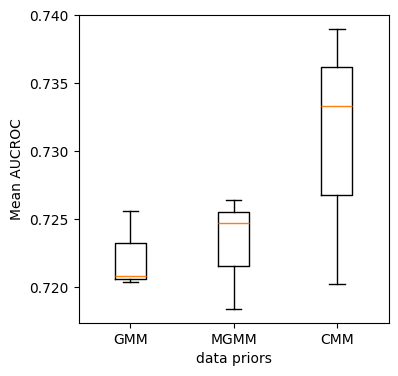

In [172]:
import matplotlib.pyplot as plt

GMM = summary_results[summary_results['data_prior_group'] == 'GMM']
MGMM = summary_results[summary_results['data_prior_group'] == 'MGMM']
CMM = summary_results[summary_results['data_prior_group'] == 'CMM']

aucroc = [GMM['average_aucroc'], MGMM['average_aucroc'], CMM['average_aucroc']]

fig, ax = plt.subplots(figsize=(4, 4))
ax.boxplot(aucroc)
ax.set_xticklabels(['GMM', 'MGMM', 'CMM'])
plt.xlabel('data priors')
plt.ylabel('Mean AUCROC')

plt.savefig('data_priors_impact_matplotlib.png')

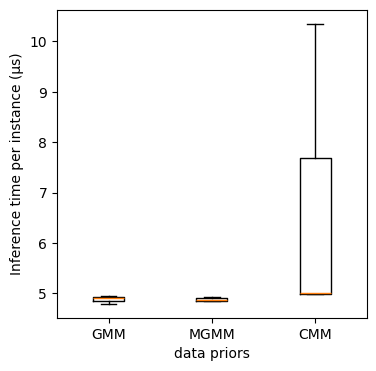

<Figure size 640x480 with 0 Axes>

In [173]:
import matplotlib.pyplot as plt
#fig = plt.figure(figsize=(4, 2))
#data = summary_results['average_aucroc']
#plt.boxplot(data)
GMM = summary_results[summary_results['data_prior_group'] == 'GMM']
MGMM = summary_results[summary_results['data_prior_group'] == 'MGMM']
CMM = summary_results[summary_results['data_prior_group'] == 'CMM']

training_time = [GMM['training_time(s)'], MGMM['training_time(s)'], CMM['training_time(s)']]
inference_time_per_instance = [GMM['inference_time(µs)'], MGMM['inference_time(µs)'], CMM['inference_time(µs)']]

#ax = fig.add_axes([0, 0, 1, 1])
#bp = ax.boxplot(training_time)
fig, ax = plt.subplots(figsize=(4, 4))
ax.boxplot(inference_time_per_instance)
ax.set_xticklabels(['GMM', 'MGMM', 'CMM'])
plt.xlabel('data priors')
plt.ylabel('Inference time per instance (µs)')

plt.show()
plt.savefig('data_priors_impact_inference.png')

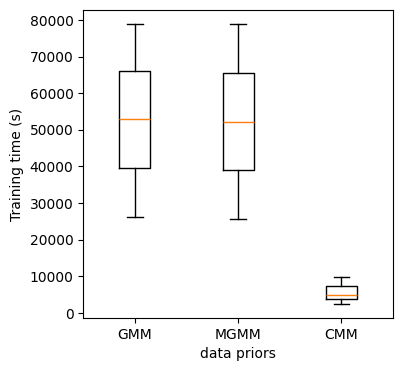

In [174]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.boxplot(training_time)
ax.set_xticklabels(['GMM', 'MGMM', 'CMM'])
plt.xlabel('data priors')
plt.ylabel('Training time (s)')

plt.savefig('data_priors_impact_training.png')